# Classical A1 -> A2 baseline: process prediction vs unsupervised scoring

Our own baseline on SWaT 2015, built from our copies of the iTrust files
(`SWaT_Dataset_Normal_v0`, `SWaT_Dataset_Attack_v0`). Train on the whole normal
file, test on the attack file, pointwise metrics. No model in sections 2-7 sees
an attack label, for training or for its threshold; section 8 is a separate
protocol that does.

All numbers come from `python src/baseline.py`; this notebook only loads and
shows them. Set `RUN = True` to rerun the pipeline here (~30 min).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

RUN = False
if RUN:
    import baseline; baseline.run(); baseline.run_attack_label()
OUT = ROOT / "results" / "baseline"; FIG = OUT / "figures"
res = json.loads((OUT / "results.json").read_text())
abl = pd.read_csv(OUT / "ablation.csv", index_col=[0, 1]); abl.index.names = ["rule", "model"]
R1, R2 = (next(k for k in res["exclusion_rules"] if k.startswith(r)) for r in ("R1", "R2"))
R3 = res["change_rule"]["label"]
COLS = ["precision", "recall", "f1", "udr", "far", "ap", "roc_auc"]
print("created", res["created"])

created 2026-10-30T19:11:28


## 1. Data: which files, how many rows, which labels

In [2]:
a = res["data_audit"]
display(pd.Series({k: v for k, v in a.items() if not isinstance(v, dict)}).to_frame("value"))
for k in ("interval_length_s", "test_timestamp_gaps_not_1s", "raw_label_strings"):
    print(f"{k}: {a.get(k)}")

,value
train_source,swat/SWaT_Dataset_Normal_v0.xlsx
test_source,../../swat-preprocess/data/swat-2015-data.csv
train_rows,496800
train_start,2015-12-22 16:00:00
train_end,2015-12-28 09:59:59
test_rows,449919
test_start,2015-12-28 10:00:00
test_end,2016-01-02 14:59:59
test_attack_rows,54621
test_attack_rate,0.121402


interval_length_s: {'min': 101, 'median': 444.0, 'max': 35900}
test_timestamp_gaps_not_1s: {'82.0': 1}
raw_label_strings: {'Normal': 395298, 'Attack': 54584, 'A ttack': 37}


## 2. Models

None of these models sees an attack label. "Supervised" means the model
predicts one part of the plant from another on normal data, and an alarm is a
prediction the plant contradicts.

| model | objective | input -> output | alarm |
|---|---|---|---|
| LinearR, RF [1], KNN, XGBoost [2] | process prediction | mapped actuator states -> sensor | any sensor's residual statistic outside its control limits (TRAIN extremes) |
| XGBoost+lags | process prediction | mapped actuator states plus their 1, 5 and 30 s lags, rolling means and differences -> sensor | same |
| 1D-CNN [3] | process prediction | last 60 s of every actuator that moves in TRAIN -> every sensor | same |
| LogisticR | state prediction | kept sensors -> each actuator's state | 1 - P(reported state), standardised per actuator, max over actuators, above mu + 3 sigma of TRAIN |
| iForest [4], K-Means [5], Elliptic Envelope [6], LOF [7], DBSCAN [8], One-Class SVM [9] | unsupervised | PCA (99% variance) of the kept columns, min-max scaled -> anomaly score | above mu + 3 sigma of TRAIN scores |
| LSTM-AE [10] | unsupervised | last 60 s of the kept columns, min-max scaled -> error reconstructing the window's last second | same |
| LSTM-forecast [11], [12] | unsupervised | the 59 s before a second -> error predicting that second | same |

Scikit-learn [13] / xgboost defaults throughout. The residual statistic is the CUSUM
statistic [14] (target = mean training residual, allowance = 0.5 training sd)
with the accumulation dropped, so each sample is tested on its own; section 8
prints both forms. The 1D-CNN is the architecture of
`models.cnn_classifier` (three Conv1d blocks, global average pooling) with a
regression head; XGBoost+lags uses the lag features of `models.xgboost_lags`.
LSTM-AE and LSTM-forecast are `models.lstm_ae` and `models.lstm_forecast`
unchanged, fit on the first 80% of the normal file with early stopping on the
last 20%. The autoencoder sees the second it scores and the forecaster does
not, so only the forecaster can flag a second that breaks the process's
dynamics without leaving its normal range.

## 3. How well actuators explain each sensor

Per sensor, the actuator inputs with the highest linear-regression R^2 on the
normal file. Iteration 1 uses this R^2 to decide which sensors may raise alarms.

In [3]:
display(pd.DataFrame(res["mapping"]).T.sort_values("r2", ascending=False).round(4))

,input_names,r2,mse
FIT201,"[MV201, P201, P202, P203, P204, P205, P206]",0.992831,0.001307
FIT504,[P501],0.986059,0.000089
FIT401,"[P401, P402, P403, P404, UV401]",0.982149,0.000111
FIT503,[P501],0.981738,0.000111
FIT501,[UV401],0.981389,0.000115
PIT501,[UV401],0.966378,0.000199
FIT301,"[MV301, MV302, MV303, MV304, P301, P302]",0.964535,0.004349
DPIT301,"[MV301, MV302, MV303, MV304, P301, P302]",0.961303,0.003978
PIT503,[UV401],0.957272,0.000256
FIT502,[UV401],0.950727,0.00029


## 4. Iteration 1 — R1: exclude the sensors the actuators do not explain

A process predictor can only check a sensor that its actuators explain; for
any other sensor the residual is just the sensor's own variation. Rule R1,
decided on the normal file only: exclude every sensor whose mapping R^2
(section 3) is below 0.5. An excluded sensor cannot raise a process-prediction
alarm; the unsupervised models and LogisticR are refit without it and their
thresholds recalibrated.

R1 excludes nine sensors. LinearR, RF and XGBoost reach F1 0.46 at a false
alarm rate of 9%, the 1D-CNN 0.44 at 0.8%; KNN, XGBoost+lags and LogisticR reach 0.59-0.70; the
classical unsupervised models 0.36-0.74; LSTM-AE 0.12 and LSTM-forecast 0.53.

In [4]:
print("R1 excludes:", ", ".join(res["exclusion_rules"][R1]))
abl.loc[R1, COLS].round(3)

R1 excludes: AIT201, AIT202, AIT401, AIT402, AIT502, AIT503, LIT301, LIT401, PIT502


,precision,recall,f1,udr,far,ap,roc_auc
model,,,,,,,
LinearR,0.429,0.496,0.460,0.504,0.091,0.527,0.715
RF,0.432,0.497,0.462,0.503,0.090,0.533,0.716
KNN,0.975,0.425,0.592,0.575,0.002,0.476,0.711
XGBoost,0.432,0.496,0.462,0.504,0.090,0.532,0.716
XGBoost+lags,0.949,0.477,0.635,0.523,0.004,0.591,0.765
1D-CNN,0.832,0.295,0.436,0.705,0.008,0.593,0.830
LogisticR,0.726,0.675,0.699,0.325,0.035,0.612,0.856
iForest,0.863,0.619,0.721,0.381,0.014,0.752,0.860
K-Means,0.697,0.687,0.692,0.313,0.041,0.568,0.863


## 5. What R1 got wrong, and the change to R2

The table breaks LinearR's false alarms down by sensor, on the attack file's
attack-free rows, next to two quantities from the normal file: the mapping R^2
that R1 uses, and how far the sensor's daily normal level moves (range of the
five daily means, as a share of the sensor's normal range).

* **False alarms follow drift, not R^2.** Every sensor that alarms on more
  than 1% of attack-free rows has a normal level that moves by 27-43% of its
  range from one normal day to the next.
* **R1 kept one of them.** AIT203 has R^2 0.60, so R1 keeps it, but its
  normal level moves by 27% of its range; on its own it alarms on 8.9% of
  attack-free rows, nearly all of LinearR's 9.1% false alarm rate under R1.
* **R1 removed four sensors that were never the problem.** AIT202, LIT301,
  LIT401 and PIT502 have low R^2 but stable levels (drift at most 7.4% of
  range) and alarm on under 0.05% of attack-free rows. Removing AIT202 cost
  the attack on it: LinearR, RF, KNN and XGBoost miss "AIT-202 set to 6"
  entirely under R1 and flag 91% of it under R2 (section 6).

So iteration 2 changes the criterion from how well the actuators explain a
sensor to how stable its normal level is. Rule R2, also decided on the normal
file only: exclude every sensor whose daily normal level moves by more than
10% of its range.

The diagnosis used the attack file's attack-free rows; the rule itself reads
only the normal file.

In [5]:
ps = pd.DataFrame(res["per_sensor"]["LinearR"]).T
ps = ps[["mapping_r2", "nominal_level_drift", "R1", "R2", "false_alarm_rate"]].rename(columns={
    "nominal_level_drift": "normal-level drift (share of range)",
    "R1": "excluded by R1", "R2": "excluded by R2",
    "false_alarm_rate": "false alarms (share of attack-free test rows)"})
num = [c for c in ps.columns if not c.startswith("excluded")]
ps[num] = ps[num].astype(float)
ps.sort_values(num[-1], ascending=False).round(3)

,mapping_r2,normal-level drift (share of range),excluded by R1,excluded by R2,false alarms (share of attack-free test rows)
AIT201,0.051,0.425,True,True,0.696
AIT402,0.053,0.326,True,True,0.469
AIT502,0.046,0.348,True,True,0.145
AIT203,0.604,0.269,False,True,0.089
AIT503,0.013,0.281,True,True,0.012
AIT501,0.509,0.093,False,False,0.001
LIT101,0.620,0.010,False,False,0.001
LIT301,0.300,0.003,True,False,0.000
DPIT301,0.961,0.010,False,False,0.000
FIT501,0.981,0.016,False,False,0.000


## 6. Iteration 2 — R2: exclude the sensors whose normal level drifts

R2 excludes six sensors: five of R1's nine plus AIT203. It keeps AIT202,
LIT301, LIT401 and PIT502.

* **Process predictors:** F1 rises from 0.44-0.64 under R1 to 0.79-0.81 and
  recall from 0.30-0.50 to 0.67-0.71; the false alarm rate is at most
  1.03% (1D-CNN; LinearR, RF, XGBoost: from 9% to 0.2-0.3%).
* **LogisticR:** F1 0.70 -> 0.71, false alarm rate 3.5% -> 4.0%.
* **Unsupervised: mixed.** iForest (0.72 -> 0.75), LOF (0.36 -> 0.41) and
  LSTM-AE (0.12 -> 0.28) improve, K-Means, One-Class SVM and LSTM-forecast
  barely move, Elliptic Envelope (0.74 -> 0.72) and DBSCAN (0.72 -> 0.61) get
  worse. R2 is the better rule for the supervised models, not for every model.
* **The LSTMs are the weakest unsupervised models on these pointwise
  metrics.** LSTM-AE: F1 0.28, recall 0.21, AP 0.43. LSTM-forecast: F1 0.53
  at a 14.5% false alarm rate, AP 0.30. Per attack, the forecaster is a
  different story (below).
* **Best under R2:** XGBoost, RF and LinearR (F1 0.81, false alarm rate
  0.2-0.3%); best unsupervised: iForest (F1 0.75, 1.4%).
* **Lags and the 1D-CNN** do not raise F1 over plain XGBoost (0.80 and 0.79
  against 0.81), but they detect attacks the row-wise regressors miss (below).

R2 excludes: AIT201, AIT203, AIT401, AIT402, AIT502, AIT503


,precision,recall,f1,udr,far,ap,roc_auc
model,,,,,,,
LinearR,0.972,0.689,0.807,0.311,0.003,0.754,0.854
RF,0.977,0.690,0.809,0.310,0.002,0.757,0.855
KNN,0.978,0.669,0.795,0.331,0.002,0.681,0.833
XGBoost,0.980,0.690,0.810,0.310,0.002,0.757,0.855
XGBoost+lags,0.962,0.683,0.799,0.317,0.004,0.714,0.850
1D-CNN,0.905,0.707,0.794,0.293,0.010,0.703,0.852
LogisticR,0.712,0.709,0.711,0.291,0.040,0.749,0.853
iForest,0.869,0.652,0.745,0.348,0.014,0.778,0.885
K-Means,0.691,0.708,0.699,0.292,0.044,0.698,0.869


R1                   R2               R2 - R1              
                     f1    far     ap     f1    far     ap      f1    far     ap
model                                                                           
LinearR           0.460  0.091  0.527  0.807  0.003  0.754   0.346 -0.088  0.226
RF                0.462  0.090  0.533  0.809  0.002  0.757   0.346 -0.088  0.225
KNN               0.592  0.002  0.476  0.795  0.002  0.681   0.203  0.001  0.204
XGBoost           0.462  0.090  0.532  0.810  0.002  0.757   0.348 -0.088  0.225
XGBoost+lags      0.635  0.004  0.591  0.799  0.004  0.714   0.164  0.000  0.123
1D-CNN            0.436  0.008  0.593  0.794  0.010  0.703   0.358  0.002  0.110
LogisticR         0.699  0.035  0.612  0.711  0.040  0.749   0.011  0.004  0.137
iForest           0.721  0.014  0.752  0.745  0.014  0.778   0.024  0.000  0.026
K-Means           0.692  0.041  0.568  0.699  0.044  0.698   0.007  0.003  0.129
EllipticEnvelope  0.738  0.000  0.723  0.717  0.007  0.718  -0.021  0.007 -0.005
LOF               0.357  0.402  0.519  0.405  0.301  0.364   0.047 -0.101 -0.156
DBSCAN            0.715  0.039  0.712  0.611  0.099  0.726  -0.104  0.060  0.014
One Class SVM     0.632  0.049  0.738  0.634  0.049  0.743   0.002  0.001  0.005
LSTM-AE           0.120  0.051  0.250  0.276  0.045  0.432   0.157 -0.006  0.182
LSTM-forecast     0.525  0.145  0.291  0.525  0.145  0.304   0.001  0.000  0.013

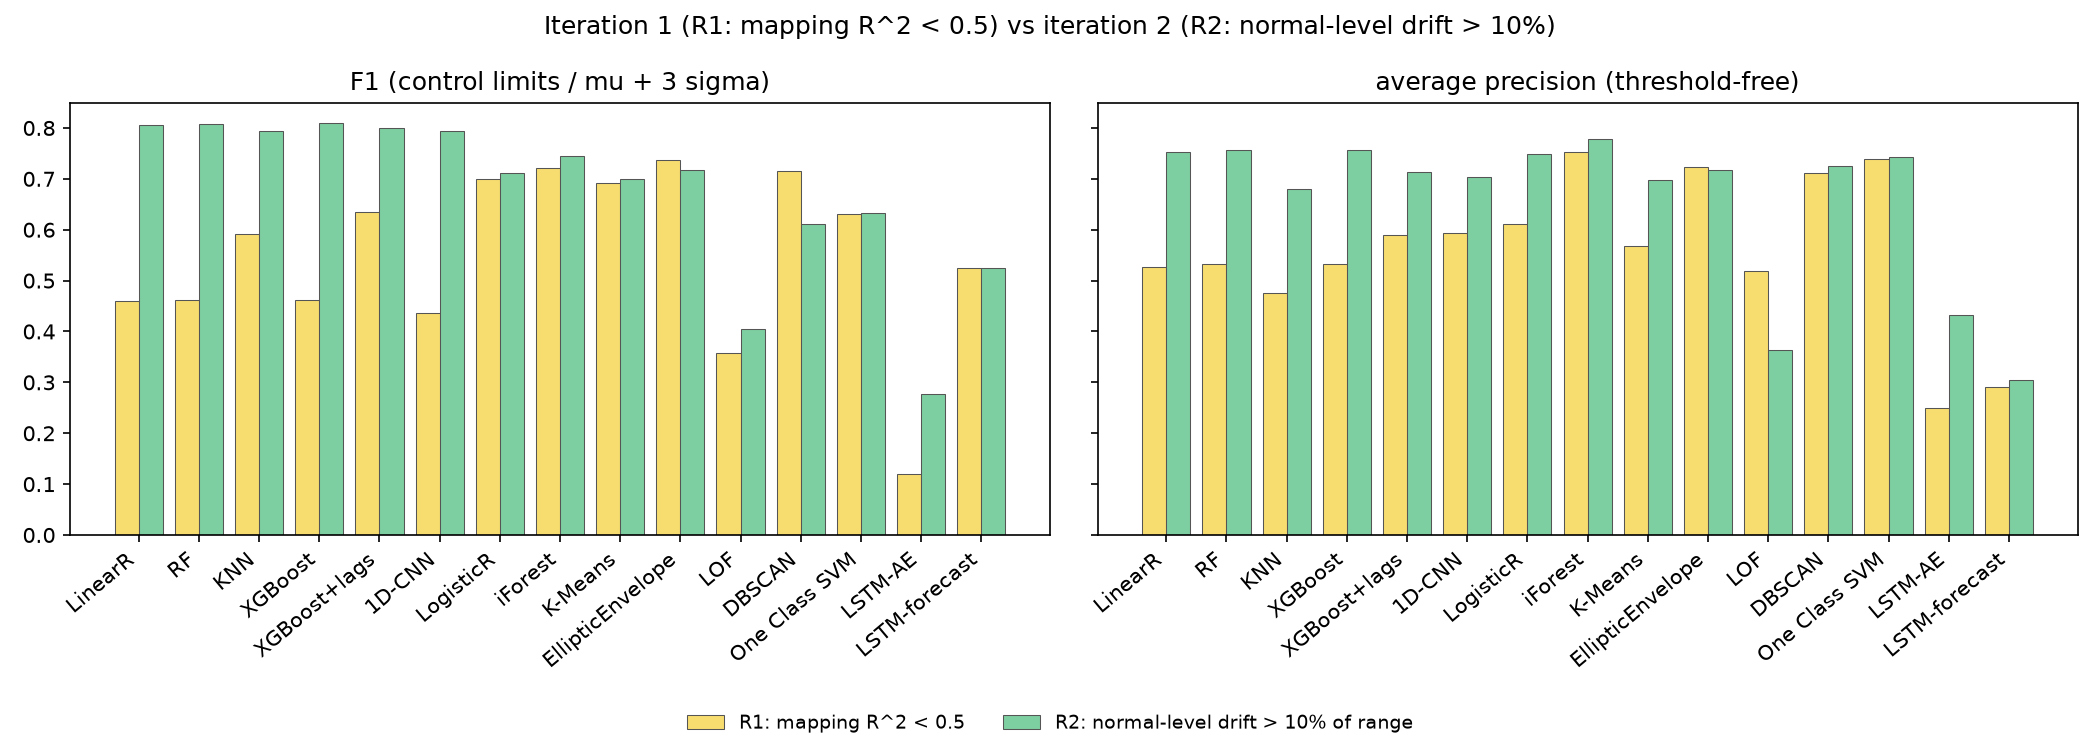

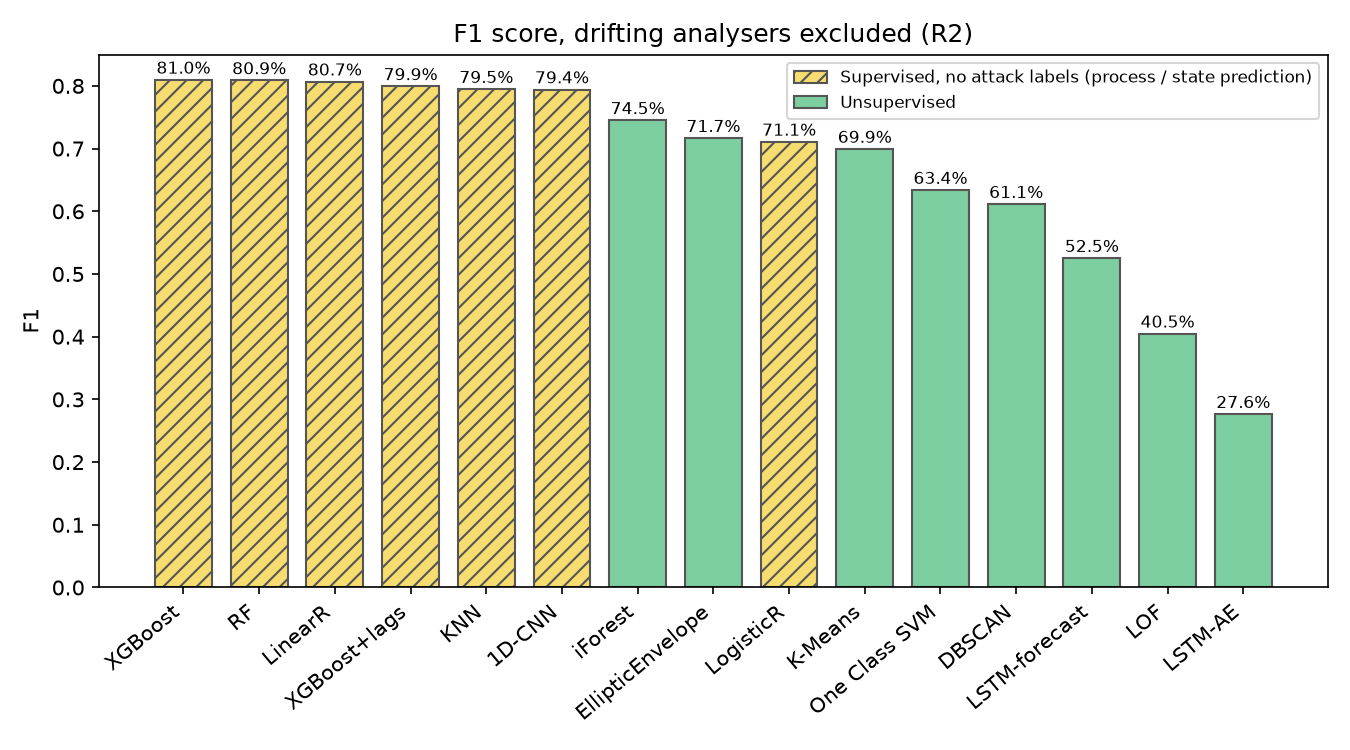

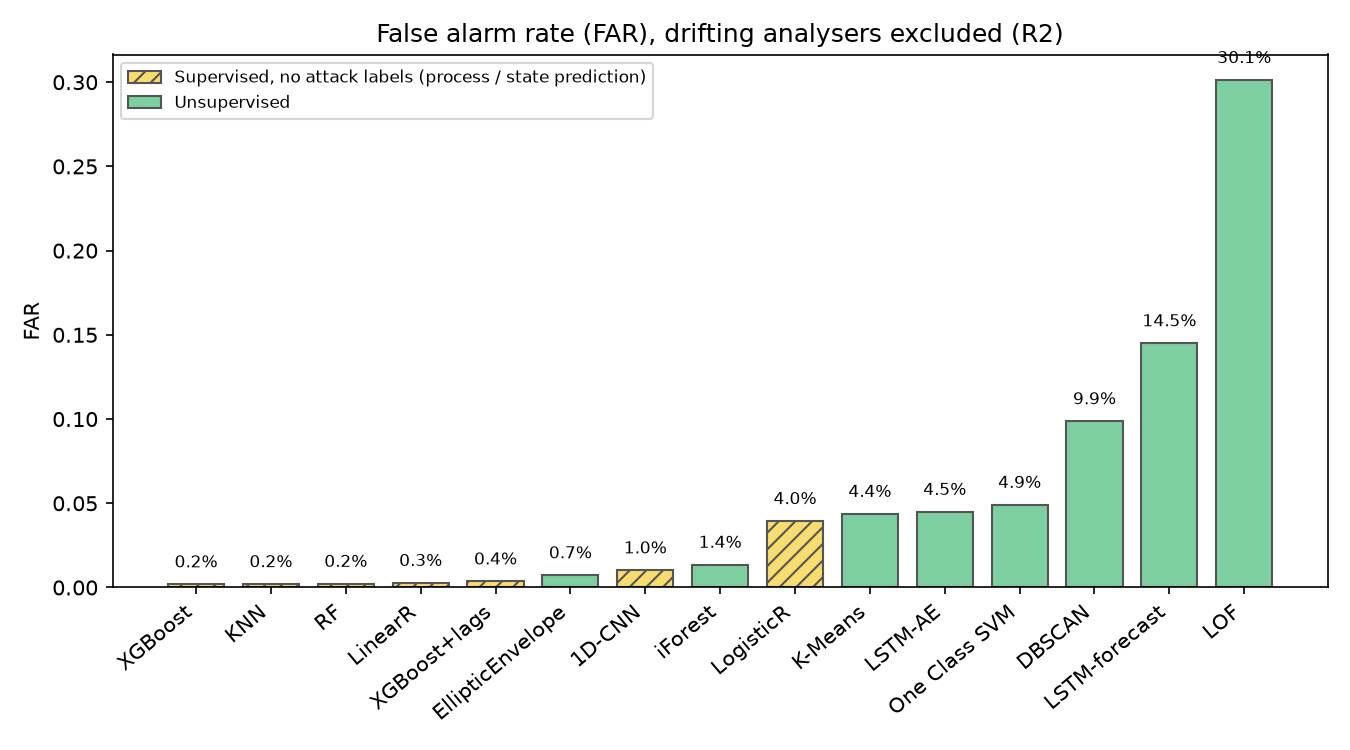

In [6]:
print("R2 excludes:", ", ".join(res["exclusion_rules"][R2]))
display(abl.loc[R2, COLS].round(3))
k = ["f1", "far", "ap"]
display(pd.concat({"R1": abl.loc[R1, k], "R2": abl.loc[R2, k], "R2 - R1": abl.loc[R2, k] - abl.loc[R1, k]},
                  axis=1).round(3))
display(Image(filename=str(FIG / "r1_vs_r2_f1_ap.png")))
for metric in ("f1", "far"):
    display(Image(filename=str(FIG / f"{metric}_R2.png")))

### Per-attack recall

Eight attacks located among the labelled intervals by their documented action
(evidence below; check it before relying on a row). Each cell is the share of
that attack's rows flagged.

The  column is the attack's category in the SWaT attack taxonomy [15],
derived from the points (sensors or actuators) its action touches and the
stages they belong to: *single stage, single point*; *single stage, multi
point* (two or more points in one stage); *multi stage, single point* (one
point in each of two or more stages); *multi stage, multi point* (two or more
stages, two or more points in at least one). [15] defines the first two; its
wording for the two multi-stage categories is almost identical, so those
follow the category names. Of the 36 attacks in [15], 26 are single stage,
single point, 4 single stage, multi point, 2 multi stage, single point and 4
multi stage, multi point; the eight here are 2, 3, 2 and 1.

Under R2:

* LinearR, RF, KNN and XGBoost flag at least 89% of three attacks (AIT-202,
  P-501 / FIT-502, UV-401) and almost none of the other five.
* XGBoost+lags adds "P-101 on, LIT-301 set to 801" (91%) and part of
  "P-203, P-205 off" (31%).
* The 1D-CNN flags at least 90% of five attacks, including
  "AIT-402, AIT-502 set to 260" (96%), whose two spoofed sensors R2 excludes.
* LSTM-forecast also flags at least 90% of five attacks, a different five:
  it catches both level-sensor spoofs, "P-101 on, LIT-301 set to 801"
  (100%) and "P-101, MV-101 on, LIT-101 set to 700" (98%; no supervised
  model flags more than 4% of it), and misses "AIT-402, AIT-502 set to 260".
  Its recall is 0.73; its 14.5% false alarm rate is what holds F1 at 0.53.
* LSTM-AE flags at least 90% of only two (AIT-202, UV-401).
* No model detects "MV-304 closed". Besides LSTM-forecast, only LOF detects
  "P-101, MV-101 on, LIT-101 set to 700" (87%).

In [7]:
att = pd.DataFrame(res["attacks"]).T.assign(evidence=pd.Series(res["attack_evidence"]))
display(att[["type", "interval", "match_deviation", "evidence"]])
for tag in ("R1", "R2"):
    print(f"iteration {tag[1]}: {tag}"); display(pd.read_csv(OUT / f"per_attack_recall_{tag}.csv", index_col=0).round(2))

,type,interval,match_deviation,evidence
AIT-202 set to 6,"single stage, single point",4,0.0,{'AIT202': 6.0}
MV-304 closed,"single stage, single point",9,0.815,{'MV304': '1.00 in state 1'}
"P-203, P-205 off","single stage, multi point",18,0.003,"{'P203': '1.00 in state 1', 'P205': '1.00 in s..."
"P-501 closed, FIT-502 set to 1.29","single stage, multi point",30,1.0,"{'P501': '0.00 in state 1', 'FIT502': 1.29}"
"P-101 on, LIT-301 set to 801","multi stage, single point",32,0.099,"{'P101': '1.00 in state 2', 'LIT301': 802.759}"
"AIT-402, AIT-502 set to 260","multi stage, single point",31,0.0,"{'AIT402': 260.0, 'AIT502': 260.0}"
"UV-401 off, AIT-502 150, P-501 on","multi stage, multi point",16,2.003,"{'UV401': '0.96 in state 1', 'AIT502': 150.0, ..."
"P-101, MV-101 on, LIT-101 set to 700","single stage, multi point",23,1.116,"{'P101': '0.96 in state 2', 'MV101': '0.03 in ..."


iteration 1: R1


,LinearR,RF,KNN,XGBoost,XGBoost+lags,1D-CNN,LogisticR,iForest,K-Means,EllipticEnvelope,LOF,DBSCAN,One Class SVM,LSTM-AE,LSTM-forecast
AIT-202 set to 6,0.0,0.0,0.00,0.0,0.91,0.97,0.90,0.00,0.00,0.0,0.90,0.90,0.00,0.74,0.90
MV-304 closed,0.0,0.0,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00
"P-203, P-205 off",0.0,0.0,0.00,0.0,0.31,0.33,0.32,0.02,0.09,0.0,0.29,0.31,0.00,0.25,0.31
"P-501 closed, FIT-502 set to 1.29",1.0,1.0,0.89,1.0,0.90,0.90,0.42,0.05,0.22,0.0,0.91,0.93,0.17,0.99,0.91
"P-101 on, LIT-301 set to 801",0.0,0.0,0.00,0.0,0.91,0.91,0.01,0.00,0.00,0.0,0.98,0.91,0.00,0.11,1.00
"AIT-402, AIT-502 set to 260",1.0,1.0,0.00,1.0,0.00,0.96,0.05,0.03,0.68,0.0,0.35,1.00,0.00,0.00,0.02
"UV-401 off, AIT-502 150, P-501 on",1.0,1.0,1.00,1.0,1.00,1.00,0.96,0.61,0.96,0.0,1.00,0.98,0.96,0.97,0.98
"P-101, MV-101 on, LIT-101 set to 700",0.0,0.0,0.00,0.0,0.00,0.04,0.04,0.00,0.00,0.0,1.00,0.04,0.00,0.06,0.97


iteration 2: R2


,LinearR,RF,KNN,XGBoost,XGBoost+lags,1D-CNN,LogisticR,iForest,K-Means,EllipticEnvelope,LOF,DBSCAN,One Class SVM,LSTM-AE,LSTM-forecast
AIT-202 set to 6,0.91,0.91,0.91,0.91,0.91,1.00,0.90,0.00,0.90,0.0,0.90,0.90,0.90,0.90,0.92
MV-304 closed,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00
"P-203, P-205 off",0.00,0.00,0.00,0.00,0.31,0.30,0.32,0.02,0.09,0.0,0.22,0.31,0.00,0.25,0.31
"P-501 closed, FIT-502 set to 1.29",0.89,0.89,0.89,0.89,0.91,0.90,0.83,0.36,0.60,0.0,0.88,1.00,0.32,0.64,0.92
"P-101 on, LIT-301 set to 801",0.00,0.00,0.00,0.00,0.91,0.91,0.01,0.00,0.00,0.0,0.51,0.95,0.00,0.02,1.00
"AIT-402, AIT-502 set to 260",0.00,0.01,0.00,0.00,0.00,0.96,0.07,0.02,0.68,0.0,0.23,1.00,0.00,0.04,0.02
"UV-401 off, AIT-502 150, P-501 on",1.00,1.00,1.00,1.00,1.00,1.00,0.96,0.96,0.96,0.0,1.00,1.00,0.96,0.96,0.98
"P-101, MV-101 on, LIT-101 set to 700",0.00,0.00,0.00,0.00,0.00,0.04,0.04,0.00,0.03,0.0,0.87,0.04,0.00,0.06,0.98


## 7. Iteration 3 — R3: add how fast each sensor changes

Under R2, XGBoost raises an alarm in only 12 of the attack file's 35 labelled
intervals. Its F1 of 0.81 rests largely on the one 10-hour interval, which
holds 66% of the attack rows. About half of the intervals it misses act on a
tank level (LIT101, LIT301, LIT401), directly (a spoofed or ramped reading) or
through the pumps the level drives. A tank level integrates inflow minus
outflow, so the actuator states at one moment set how fast the level
changes, not where it is: R1's mapping R^2 for LIT301 and LIT401 is 0.30 and
0.34.

Rule R3, decided on the normal file only: keep R2's sensors, and add as
further process-prediction targets the change of a sensor over the last
w seconds (x_t - x_{t-w}), predicted from the mean state of every moving
actuator over the same w seconds (the 1D-CNN: from their last w seconds). A
sensor gets a change target when the actuators explain its change with linear
R^2 >= 0.5, R1's bar. w is the shortest of 30, 60, 90, 120, 180 and 300 s at
which every tank level passes that bar: 90 s (LIT401 reaches 0.499 at 60 s).
Change targets use the residual statistic and control limits of section 2;
the alarm is any value or change target outside its limits.

Eleven sensors pass at 90 s: the three tank levels, FIT201, DPIT301, FIT301,
FIT401, FIT501, PIT501, PIT503 and FIT601. None is one of R2's exclusions.
R3 changes only the process predictors; LogisticR and the unsupervised models
see R2's sensors, so their R3 rows repeat R2's.

The diagnosis that led to R3 used the attack file (which intervals R2
misses); the rule itself reads only the normal file. Five other variants were
also scored on the attack file and set aside: replacing the level targets
with change targets instead of adding them, change targets for the tank
levels only, change targets for R2's drifting analysers, control limits taken
from the normal file after its start-up hour, and residuals re-centred on
their trailing 24-hour median. R3's gain is therefore
somewhat optimistic.

In [8]:
cr = res["change_rule"]
print(f"R3: w = {cr['window_s']} s; change targets:", ", ".join(cr["targets"]))
ch = pd.DataFrame(cr["change_r2"]).astype(float)
ch.columns = [f"change R^2, {c} s" for c in ch.columns]
ch.insert(0, "level R^2 (R1)", pd.Series({k: v["r2"] for k, v in res["mapping"].items()}))
ch.insert(1, "R3 target", ch.index.isin(cr["targets"]))
ch.sort_values(f"change R^2, {cr['window_s']} s", ascending=False).round(3)

R3: w = 90 s; change targets: LIT101, FIT201, DPIT301, FIT301, LIT301, FIT401, LIT401, FIT501, PIT501, PIT503, FIT601


,level R^2 (R1),R3 target,"change R^2, 30 s","change R^2, 60 s","change R^2, 90 s","change R^2, 120 s","change R^2, 180 s","change R^2, 300 s"
LIT101,0.620,True,0.600,0.856,0.927,0.956,0.978,0.994
FIT601,0.640,True,0.691,0.820,0.812,0.763,0.773,0.761
LIT301,0.300,True,0.425,0.630,0.772,0.847,0.916,0.977
FIT201,0.993,True,0.753,0.755,0.755,0.757,0.764,0.785
DPIT301,0.961,True,0.362,0.556,0.629,0.674,0.656,0.640
LIT401,0.340,True,0.316,0.499,0.615,0.690,0.810,0.945
FIT301,0.965,True,0.317,0.535,0.600,0.608,0.597,0.586
PIT503,0.957,True,0.426,0.511,0.571,0.582,0.630,0.670
FIT401,0.982,True,0.433,0.515,0.567,0.578,0.627,0.668
FIT501,0.981,True,0.435,0.515,0.567,0.577,0.627,0.668


### R3 results

* **Process predictors:** XGBoost F1 0.81 -> 0.87 and XGBoost+lags 0.80 ->
  0.87, recall 0.69 -> 0.82-0.83. LinearR 0.81 -> 0.83, RF 0.81 -> 0.82,
  KNN 0.795 -> 0.802. The 1D-CNN is the one that does not gain (0.794 -> 0.788).
* **Attacks reached:** XGBoost raises an alarm in 28 of the 35 labelled
  intervals (12 under R2); threshold-free, its AP rises from 0.757 to 0.789
  and ROC-AUC from 0.855 to 0.904.
* **The cost is false alarms.** XGBoost's false alarm rate rises from 0.2% to
  1.0% and its precision falls from 0.98 to 0.92. False alarm events rise from
  37 to 269 over the attack file's 110 attack-free hours. LinearR pays least: 0.6%, 72 events.
* **Best under R3:** XGBoost and XGBoost+lags (F1 0.87, false alarm rate
  1.0-1.1%); the best unsupervised model is still iForest (F1 0.75, 1.4%).

R3: R2 + 90-s change, change R^2 >= 0.5


,precision,recall,f1,udr,far,ap,roc_auc,intervals_detected,false_alarm_events
model,,,,,,,,,
LinearR,0.948,0.740,0.831,0.260,0.006,0.777,0.864,19.0,72.0
RF,0.925,0.734,0.818,0.266,0.008,0.744,0.861,25.0,178.0
KNN,0.903,0.722,0.802,0.278,0.011,0.607,0.853,26.0,190.0
XGBoost,0.918,0.819,0.866,0.181,0.010,0.789,0.904,28.0,269.0
XGBoost+lags,0.909,0.826,0.866,0.174,0.011,0.780,0.910,28.0,269.0
1D-CNN,0.880,0.713,0.788,0.287,0.013,0.705,0.854,22.0,111.0
LogisticR,0.712,0.709,0.711,0.291,0.040,0.749,0.853,29.0,1724.0
iForest,0.869,0.652,0.745,0.348,0.014,0.778,0.885,22.0,740.0
K-Means,0.691,0.708,0.699,0.292,0.044,0.698,0.869,26.0,777.0


R2                                                                R3                                                            R3 - R2                                          \
                 f1 recall    far     ap intervals_detected false_alarm_events     f1 recall    far     ap intervals_detected false_alarm_events      f1 recall    far     ap intervals_detected   
model                                                                                                                                                                                              
LinearR       0.807  0.689  0.003  0.754               13.0               26.0  0.831  0.740  0.006  0.777               19.0               72.0   0.025  0.051  0.003  0.024                6.0   
RF            0.809  0.690  0.002  0.757               14.0               90.0  0.818  0.734  0.008  0.744               25.0              178.0   0.010  0.044  0.006 -0.014               11.0   
KNN           0.795  0.669  0.002  0.681               12.0               47.0  0.802  0.722  0.011  0.607               26.0              190.0   0.007  0.052  0.009 -0.074               14.0   
XGBoost       0.810  0.690  0.002  0.757               12.0               37.0  0.866  0.819  0.010  0.789               28.0              269.0   0.056  0.129  0.008  0.032               16.0   
XGBoost+lags  0.799  0.683  0.004  0.714               13.0               46.0  0.866  0.826  0.011  0.780               28.0              269.0   0.066  0.143  0.008  0.066               15.0   
1D-CNN        0.794  0.707  0.010  0.703               22.0               79.0  0.788  0.713  0.013  0.705               22.0              111.0  -0.006  0.006  0.003  0.002                0.0   

                                 
             false_alarm_events  
model                            
LinearR                    46.0  
RF                         88.0  
KNN                       143.0  
XGBoost                   232.0  
XGBoost+lags              223.0  
1D-CNN                     32.0

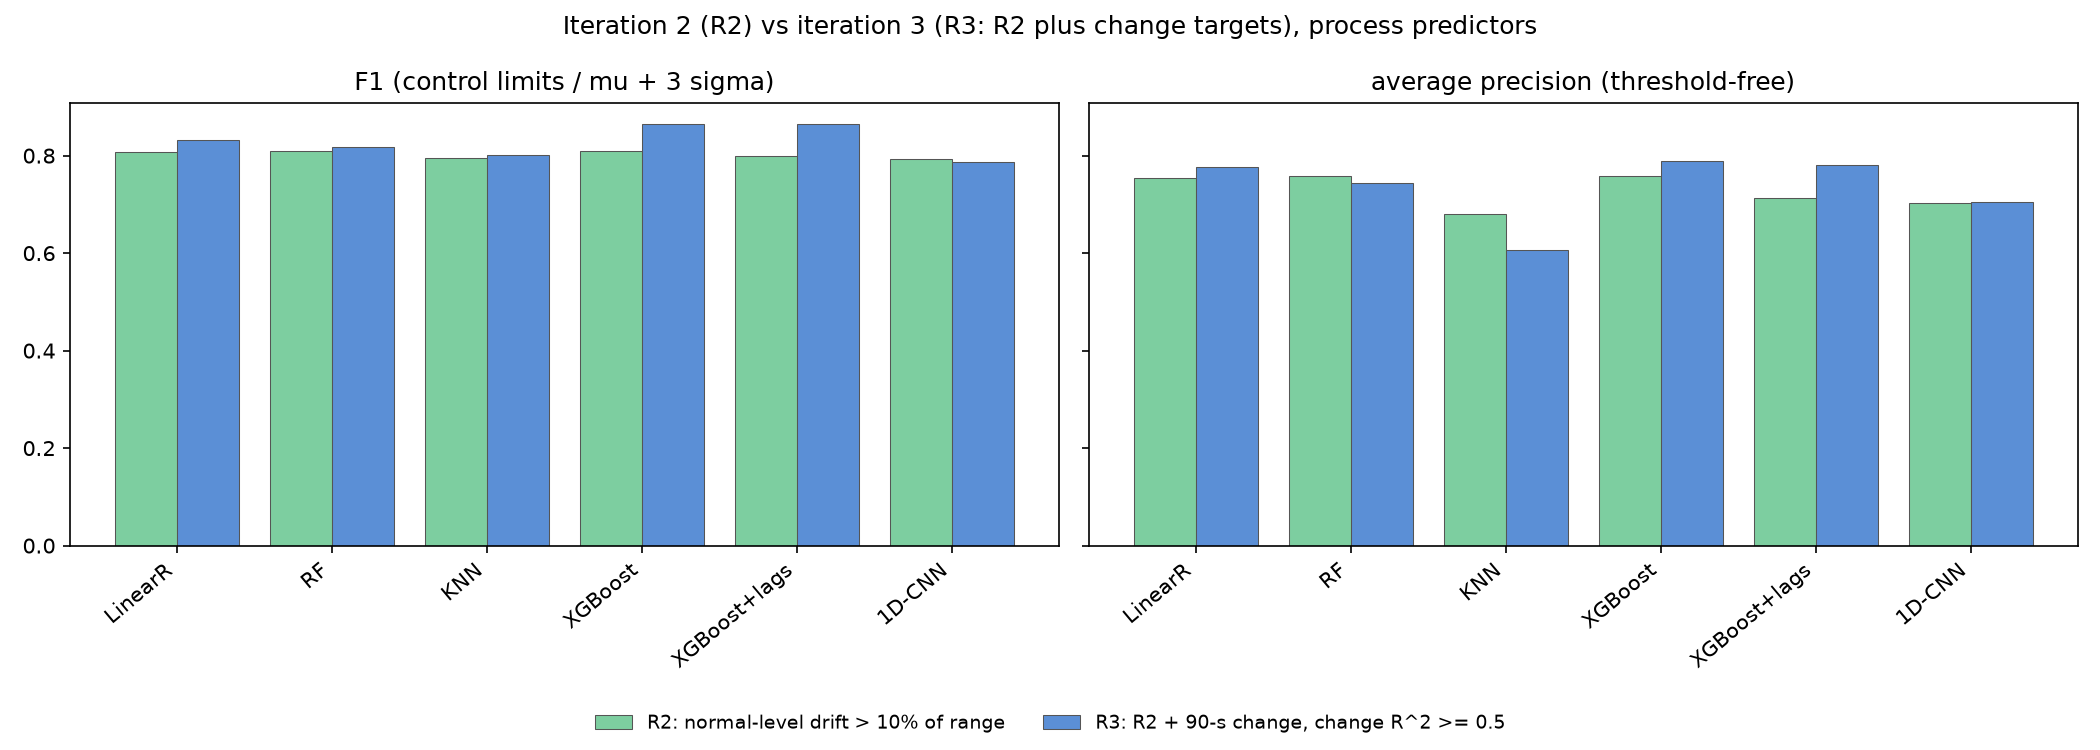

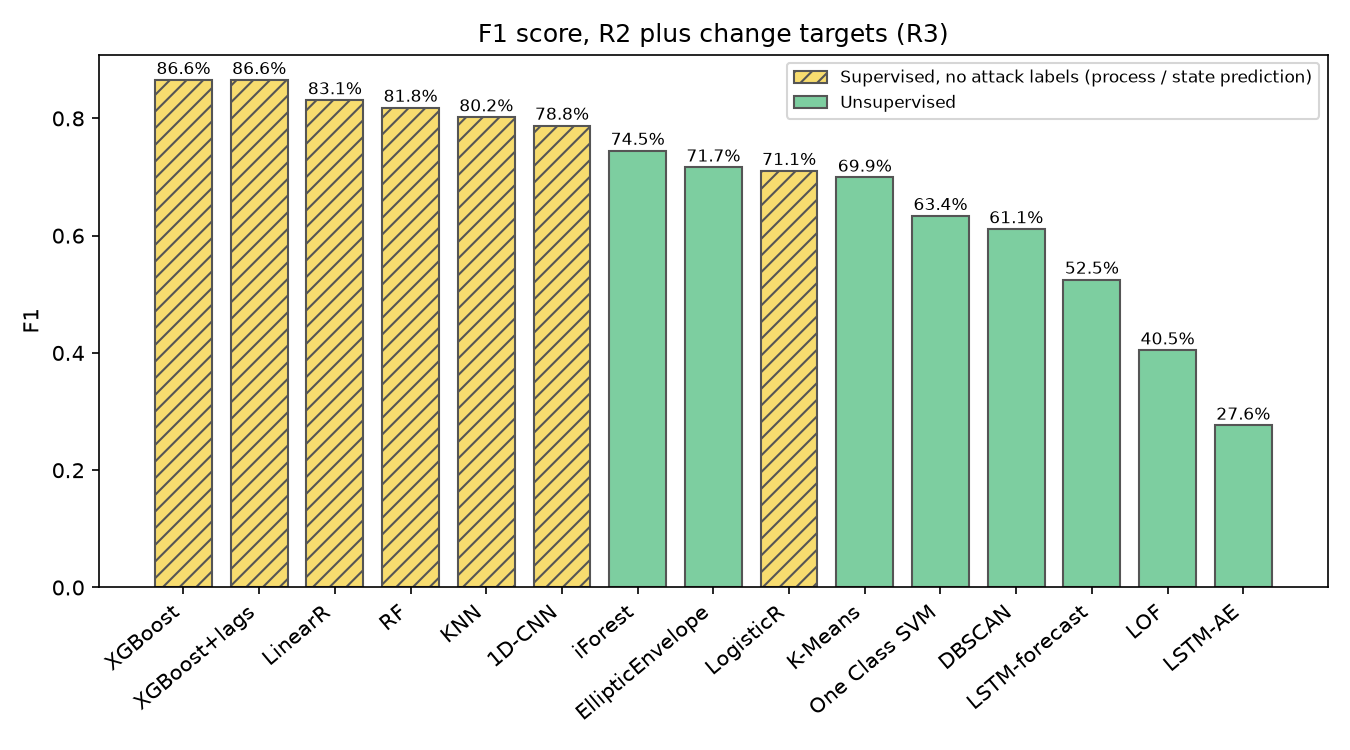

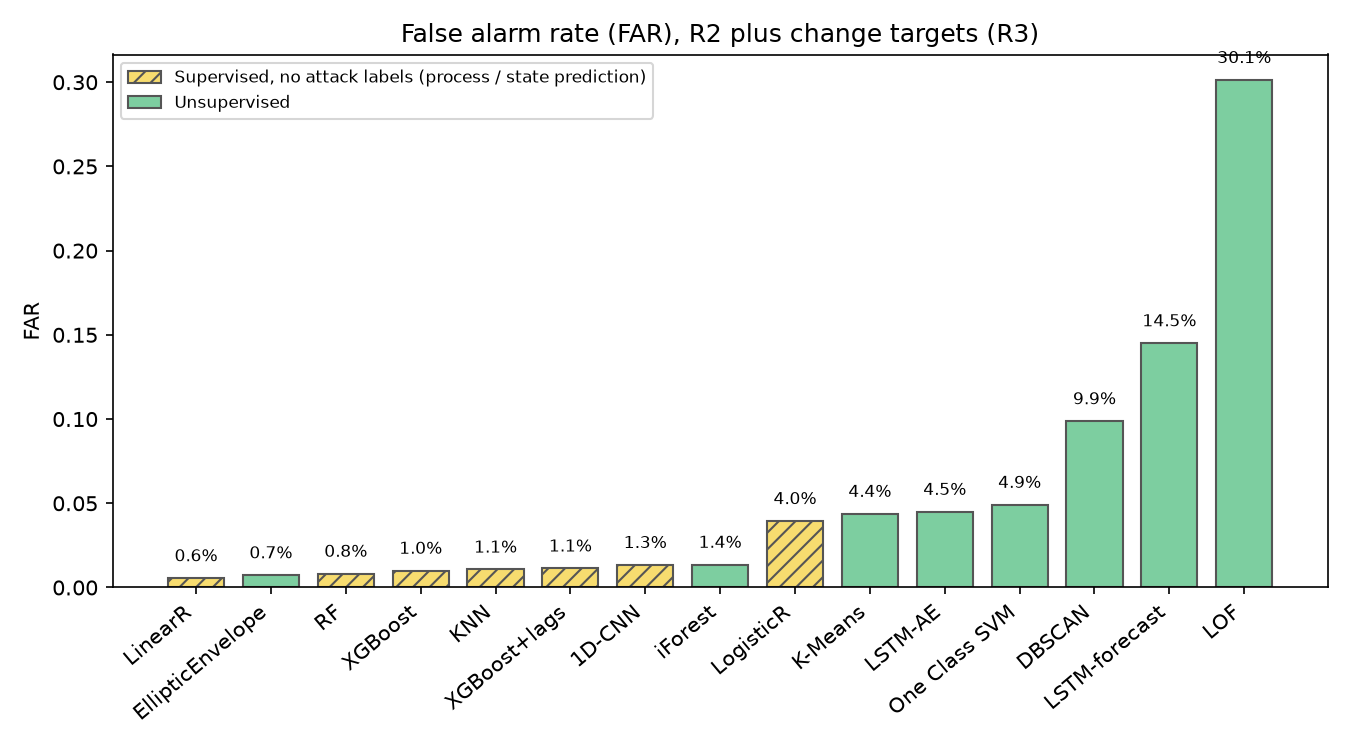

In [9]:
P = res["change_rule"]["applies_to"]
EV = ["intervals_detected", "false_alarm_events"]
print(R3)
display(abl.loc[R3, COLS + EV].round(3))
k = ["f1", "recall", "far", "ap"] + EV
display(pd.concat({"R2": abl.loc[R2].loc[P, k], "R3": abl.loc[R3].loc[P, k],
                   "R3 - R2": abl.loc[R3].loc[P, k] - abl.loc[R2].loc[P, k]}, axis=1).round(3))
display(Image(filename=str(FIG / "r2_vs_r3_f1_ap.png")))
for metric in ("f1", "far"):
    display(Image(filename=str(FIG / f"{metric}_R3.png")))

### Per change target and per attack

For XGBoost, no change target alarms on more than 0.3% of the attack-free
rows (LIT301 0.29%, LIT101 0.24%). The DPIT301 and FIT301 change targets
flag about 34,000 attack rows each.

Per attack, R3 against R2:

* XGBoost and XGBoost+lags flag 100% of "P-101, MV-101 on, LIT-101 set to
  700" (0% under R2). Before R3, only LSTM-forecast (98%) and LOF (87%)
  caught it.
* "P-203, P-205 off" rises from 0% to 31-56% for LinearR, RF, KNN and
  XGBoost, and from about 30% to 54-56% for XGBoost+lags and the 1D-CNN.
* "AIT-202 set to 6" rises from 91% to 100% for every row-wise process
  predictor; RF, KNN and XGBoost now flag 22% of "P-101 on, LIT-301 set to
  801".
* Still missed: "MV-304 closed" (no model flags more than 2% of it), and
  "AIT-402, AIT-502 set to 260" by every process predictor except the 1D-CNN
  (96%; the others at most 6%), because R2 excludes both spoofed sensors.

In [10]:
pc = pd.read_csv(OUT / "per_change_target.csv", index_col=[0, 1])
display(pc.loc["XGBoost"].round(4))
print("iteration 3: R3"); display(pd.read_csv(OUT / "per_attack_recall_R3.csv", index_col=0).round(2))

,change_r2,pred_var_ratio,false_alarm_rows,false_alarm_rate,attack_rows_flagged
change90s:LIT301,0.7723,0.9934,1152,0.0029,3569
change90s:LIT101,0.9270,0.9939,947,0.0024,2849
change90s:DPIT301,0.6289,0.9962,736,0.0019,34544
change90s:FIT201,0.7555,0.9970,437,0.0011,544
change90s:FIT401,0.5667,0.9405,382,0.0010,339
change90s:FIT501,0.5666,0.9452,330,0.0008,124
change90s:FIT301,0.5995,0.9981,250,0.0006,33961
change90s:LIT401,0.6146,0.9513,147,0.0004,846
change90s:PIT503,0.5709,0.9536,100,0.0003,112
change90s:PIT501,0.5544,0.9464,99,0.0003,113


iteration 3: R3


,LinearR,RF,KNN,XGBoost,XGBoost+lags,1D-CNN,LogisticR,iForest,K-Means,EllipticEnvelope,LOF,DBSCAN,One Class SVM,LSTM-AE,LSTM-forecast
AIT-202 set to 6,1.00,1.00,1.00,1.00,1.00,1.00,0.90,0.00,0.90,0.0,0.90,0.90,0.90,0.90,0.92
MV-304 closed,0.00,0.01,0.02,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00
"P-203, P-205 off",0.49,0.31,0.42,0.56,0.56,0.54,0.32,0.02,0.09,0.0,0.22,0.31,0.00,0.25,0.31
"P-501 closed, FIT-502 set to 1.29",0.89,0.89,0.89,0.89,0.91,0.90,0.83,0.36,0.60,0.0,0.88,1.00,0.32,0.64,0.92
"P-101 on, LIT-301 set to 801",0.00,0.22,0.22,0.22,0.91,0.91,0.01,0.00,0.00,0.0,0.51,0.95,0.00,0.02,1.00
"AIT-402, AIT-502 set to 260",0.00,0.01,0.06,0.00,0.00,0.96,0.07,0.02,0.68,0.0,0.23,1.00,0.00,0.04,0.02
"UV-401 off, AIT-502 150, P-501 on",1.00,1.00,1.00,1.00,1.00,1.00,0.96,0.96,0.96,0.0,1.00,1.00,0.96,0.96,0.98
"P-101, MV-101 on, LIT-101 set to 700",0.00,0.04,0.04,1.00,1.00,0.04,0.04,0.00,0.03,0.0,0.87,0.04,0.00,0.06,0.98


## 8. Attack-label classifiers (separate protocol)

The attack-label versions of the three new models (`xgboost_lags`,
`logistic_regression`, `cnn_classifier` in `models.py`) learn from labelled
attack rows, and the normal file has none. They are trained on the
episode-stratified split instead: the normal and attack files in time order,
whole attack incidents assigned to train, validation or test by the stage they
target, with purged boundaries. Threshold: the 97th percentile of validation
normal-row scores. All 51 columns, no R1, R2 or R3 rule.

The test set is different (88,910 rows, 4.8% attack, incidents none of the
classifiers saw in training), so this table is not comparable row for row with
sections 4-7.

* LogisticR: F1 0.32, AP 0.51. 1D-CNN: F1 0.19, AP 0.12.
* XGBoost+lags: F1 0.002, AP 0.046 against a 0.048 attack share, ROC-AUC
  0.50: no better than chance on attacks it was not trained on.

In [11]:
al = json.loads((OUT / "attack_label.json").read_text())
print(al["split"])
print(f"\ntest: {al['test_rows']:,} rows, {al['test_attack_rate']:.2%} attack | threshold: {al['threshold']}")
print("models:", al["models"])
pd.DataFrame(al["metrics"]).T[COLS].astype(float).round(3)

swat-stratified: 51 features
  train  708,650 rows  anomaly rate 0.0646
  val    116,159 rows  anomaly rate 0.0395
  test    88,910 rows  anomaly rate 0.0478

test: 88,910 rows, 4.78% attack | threshold: 97.0th percentile of validation normal-row scores
models: {'XGBoost+lags': 'xgboost+lags[1, 5, 30]', 'LogisticR': 'logistic_regression', '1D-CNN': 'cnn_classifier(w=60,f=64)'}


,precision,recall,f1,udr,far,ap,roc_auc
XGBoost+lags,0.005,0.001,0.002,0.999,0.011,0.046,0.497
LogisticR,0.233,0.501,0.318,0.499,0.083,0.508,0.661
1D-CNN,0.162,0.224,0.188,0.776,0.058,0.124,0.674


## 9. Decision record

In [12]:
print(json.dumps(res["defaults"], indent=1))
rec = res["decision_records"]["LinearR"]
print(rec["recurrence"]); print(rec["alarm"])
display(pd.DataFrame(rec["per_sensor"]).T.round(5))
cnn = res["decision_records"]["1D-CNN"]["regressor_params"]
print("1D-CNN |", {k: v for k, v in cnn.items() if k != "val_mse_history"})
lr = res["decision_records"]["LogisticR"]
print("LogisticR |", lr["alarm"], "| threshold", round(lr["threshold_train_stats"], 3))
for m_ in ("iForest", "K-Means", "EllipticEnvelope", "LOF", "DBSCAN", "One Class SVM", "LSTM-AE", "LSTM-forecast"):
    r = res["decision_records"][m_]
    print(m_, "| threshold", round(r["threshold_train_stats"], 4), "|", r.get("params"))
cr = res["change_rule"]
print("R3 |", {k: v for k, v in cr.items() if k != "change_r2"})
print("LinearR change targets |", res["decision_records"]["LinearR"]["change_targets"]["alarm"])
display(pd.DataFrame(res["decision_records"]["LinearR"]["change_targets"]["per_sensor"]).T.round(5))

{
 "data_profile": "full_normal",
 "seed": 42,
 "pca_variance": 0.99,
 "k_sigma": 3.0,
 "residual_allowance_sd": 0.5,
 "residual_mode": "pointwise",
 "subsample": {
  "lof": 20000,
  "dbscan": 10000,
  "ocsvm": 10000
 },
 "threshold_stats": "train",
 "mapping_r2_rule": 0.5,
 "drift_rule": 0.1,
 "change_windows": [
  30,
  60,
  90,
  120,
  180,
  300
 ],
 "lags": [
  1,
  5,
  30
 ],
 "cnn": {
  "window": 60,
  "filters": 64,
  "epochs": 15,
  "batch_size": 256,
  "lr": 0.001,
  "train_stride": 5,
  "patience": 3,
  "holdout": 0.2
 },
 "lstm": {
  "train_stride": 5,
  "holdout": 0.2
 }
}
{'pointwise': 'SH_i = max(0, x_{i-1} - T - b); SL_i = min(0, x_{i-1} - T + b)', 'accumulating': 'SH_i = max(0, SH_{i-1} + x_i - T - b); SL_i = min(0, SL_{i-1} + x_i - T + b)'}
any sensor with SH > UCL or SL < LCL; UCL/LCL = max/min on TRAIN


,target,allowance_b,pointwise_UCL,pointwise_LCL,accumulating_UCL,accumulating_LCL
FIT101,-0.0,0.04925,1.75956,-0.57232,19.43136,-1.93127
LIT101,-0.0,0.04340,0.27718,-0.86854,583.60489,-3543.72149
AIT201,0.0,0.08355,0.25728,-0.62221,10899.91824,-17835.36787
AIT202,0.0,0.05377,0.68024,-0.17328,3810.98467,-279.94964
AIT203,-0.0,0.05829,0.70518,-0.08424,7920.71818,-114.61671
FIT201,0.0,0.01808,1.07473,-0.20363,25.12415,-0.89008
DPIT301,0.0,0.03154,1.05397,-0.55577,7.11940,-181.07256
FIT301,-0.0,0.03297,0.91336,-0.99535,7.84790,-139.74788
LIT301,-0.0,0.04837,0.11787,-0.65384,79.95413,-2598.78368
FIT501,0.0,0.00537,0.64165,-0.97244,531.09284,-283.54448


1D-CNN | {'window': 60, 'filters': 64, 'epochs': 15, 'batch_size': 256, 'lr': 0.001, 'train_stride': 5, 'patience': 3, 'holdout': 0.2, 'n_inputs': 15, 'device': 'mps', 'best_epoch': 1}
LogisticR | max over actuators of standardised 1 - P(reported state) > mu + 3 sigma of TRAIN | threshold 10.604
iForest | threshold 0.5959 | {'bootstrap': 'False', 'contamination': 'auto', 'max_features': '1.0', 'max_samples': 'auto', 'n_estimators': '100', 'n_jobs': '-1', 'random_state': '42', 'verbose': '0', 'warm_start': 'False'}
K-Means | threshold 1.4231 | {'algorithm': 'lloyd', 'copy_x': 'True', 'init': 'k-means++', 'max_iter': '300', 'n_clusters': '8', 'n_init': 'auto', 'random_state': '42', 'tol': '0.0001', 'verbose': '0'}
EllipticEnvelope | threshold 89617.1671 | {'estimator': 'MinCovDet', 'random_state': 42}
LOF | threshold 3.2529 | {'algorithm': 'auto', 'contamination': 'auto', 'leaf_size': '30', 'metric': 'minkowski', 'metric_params': 'None', 'n_jobs': '-1', 'n_neighbors': '20', 'novelty': 'T

,target,allowance_b,pointwise_UCL,pointwise_LCL,accumulating_UCL,accumulating_LCL
change90s:LIT101,0.0,0.00373,0.79170,-0.75482,16.51254,-15.80332
change90s:FIT201,-0.0,0.05099,0.51519,-2.27163,319.29041,-476.99887
change90s:DPIT301,0.0,0.07061,0.83487,-0.87390,51.51314,-148.08204
change90s:FIT301,0.0,0.08244,0.74721,-0.86068,63.46135,-179.06056
change90s:LIT301,0.0,0.00509,0.70480,-0.68409,35.11954,-37.83032
change90s:FIT401,0.0,0.00486,0.77379,-0.71828,40.86100,-47.84310
change90s:LIT401,0.0,0.00688,0.78706,-0.77377,56.12256,-57.48864
change90s:FIT501,0.0,0.00482,0.76297,-0.70986,41.01393,-47.69943
change90s:PIT501,0.0,0.00492,0.72107,-0.66747,45.01870,-49.20564
change90s:PIT503,0.0,0.00519,0.82178,-0.74807,42.52157,-52.73744


## References

[1] L. Breiman, "Random forests," *Mach. Learn.*, vol. 45, no. 1, pp. 5–32,
2001, doi: [10.1023/A:1010933404324](https://doi.org/10.1023/A:1010933404324).

[2] T. Chen and C. Guestrin, "XGBoost: A scalable tree boosting system," in
*Proc. 22nd ACM SIGKDD Int. Conf. Knowl. Discov. Data Mining*, 2016,
pp. 785–794, doi: [10.1145/2939672.2939785](https://doi.org/10.1145/2939672.2939785).

[3] Z. Wang, W. Yan, and T. Oates, "Time series classification from scratch
with deep neural networks: A strong baseline," in *Proc. Int. Joint Conf.
Neural Netw. (IJCNN)*, 2017, pp. 1578–1585, doi:
[10.1109/IJCNN.2017.7966039](https://doi.org/10.1109/IJCNN.2017.7966039).

[4] F. T. Liu, K. M. Ting, and Z.-H. Zhou, "Isolation forest," in *Proc. 8th
IEEE Int. Conf. Data Mining (ICDM)*, 2008, pp. 413–422, doi:
[10.1109/ICDM.2008.17](https://doi.org/10.1109/ICDM.2008.17).

[5] S. Lloyd, "Least squares quantization in PCM," *IEEE Trans. Inf. Theory*,
vol. 28, no. 2, pp. 129–137, 1982, doi:
[10.1109/TIT.1982.1056489](https://doi.org/10.1109/TIT.1982.1056489).

[6] P. J. Rousseeuw and K. Van Driessen, "A fast algorithm for the minimum
covariance determinant estimator," *Technometrics*, vol. 41, no. 3,
pp. 212–223, 1999, doi:
[10.1080/00401706.1999.10485670](https://doi.org/10.1080/00401706.1999.10485670).

[7] M. M. Breunig, H.-P. Kriegel, R. T. Ng, and J. Sander, "LOF: Identifying
density-based local outliers," in *Proc. ACM SIGMOD Int. Conf. Manage. Data*,
2000, pp. 93–104, doi: [10.1145/342009.335388](https://doi.org/10.1145/342009.335388).

[8] M. Ester, H.-P. Kriegel, J. Sander, and X. Xu, "A density-based algorithm
for discovering clusters in large spatial databases with noise," in *Proc. 2nd
Int. Conf. Knowl. Discov. Data Mining (KDD)*, 1996, pp. 226–231.

[9] B. Schölkopf, J. C. Platt, J. Shawe-Taylor, A. J. Smola, and
R. C. Williamson, "Estimating the support of a high-dimensional distribution,"
*Neural Comput.*, vol. 13, no. 7, pp. 1443–1471, 2001, doi:
[10.1162/089976601750264965](https://doi.org/10.1162/089976601750264965).

[10] P. Malhotra, A. Ramakrishnan, G. Anand, L. Vig, P. Agarwal, and G. Shroff,
"LSTM-based encoder-decoder for multi-sensor anomaly detection," presented at
the ICML Anomaly Detection Workshop, New York, NY, USA, 2016,
[arXiv:1607.00148](https://arxiv.org/abs/1607.00148).

[11] P. Malhotra, L. Vig, G. Shroff, and P. Agarwal, "Long short term memory
networks for anomaly detection in time series," in *Proc. Eur. Symp. Artif.
Neural Netw. (ESANN)*, Bruges, Belgium, 2015.
[PDF](https://www.esann.org/sites/default/files/proceedings/legacy/es2015-56.pdf)

[12] K. Hundman, V. Constantinou, C. Laporte, I. Colwell, and T. Soderstrom,
"Detecting spacecraft anomalies using LSTMs and nonparametric dynamic
thresholding," in *Proc. 24th ACM SIGKDD Int. Conf. Knowl. Discov. Data
Mining*, 2018, pp. 387–395, doi:
[10.1145/3219819.3219845](https://doi.org/10.1145/3219819.3219845).

[13] F. Pedregosa *et al.*, "Scikit-learn: Machine learning in Python,"
*J. Mach. Learn. Res.*, vol. 12, pp. 2825–2830, 2011.
[Online](https://jmlr.org/papers/v12/pedregosa11a.html)

[14] E. S. Page, "Continuous inspection schemes," *Biometrika*, vol. 41,
no. 1/2, pp. 100–115, 1954, doi:
[10.1093/biomet/41.1-2.100](https://doi.org/10.1093/biomet/41.1-2.100).

[15] J. Goh, S. Adepu, K. N. Junejo, and A. Mathur, "A dataset to support
research in the design of secure water treatment systems," in *Critical
Information Infrastructures Security (CRITIS 2016)*, ser. Lecture Notes in
Computer Science, vol. 10242. Cham, Switzerland: Springer, 2017, pp. 88–99,
doi: [10.1007/978-3-319-71368-7_8](https://doi.org/10.1007/978-3-319-71368-7_8).